# **Quantum-Enhanced Multimodal Learning for Explainable Brain Stroke Detection Using CT and MRI Images**

# Install Library

In [4]:
!pip install kagglehub
!pip install pydicom
!pip install SimpleITK

# Load Dataset

In [5]:
import kagglehub

path = kagglehub.dataset_download("turkertuncer/multimodal-stroke-image-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/turkertuncer/multimodal-stroke-image-dataset


# Verify Dataset

In [6]:
import os

print("Dataset Path:", path)
print("\nMain Directory Contents:")

for item in os.listdir(path):
    item_path = os.path.join(path, item)
    if os.path.isdir(item_path):
        print(f"\n{item}/")
        for sub_item in os.listdir(item_path)[:10]:
            print("   ", sub_item)
    else:
        print(f"{item}")

print("\nDataset Verification:")
print("Path Exists:", os.path.exists(path))
print("Total Files:", sum(len(files) for _, _, files in os.walk(path)))
print("Total Folders:", sum(len(dirs) for _, dirs, _ in os.walk(path)))

Dataset Path: /kaggle/input/datasets/turkertuncer/multimodal-stroke-image-dataset

Main Directory Contents:

deep/
    test
    train

Dataset Verification:
Path Exists: True
Total Files: 5337
Total Folders: 13


In [7]:
import os
from PIL import Image

dataset_path = os.path.join(path, "deep")

folders = {
    "Train": {
        "1- Stroke": ["StrokeBT", "StrokeMR"],
        "2- Control": ["NormalBT", "NormalMR"]
    },
    "Test": {
        "": ["normalBT", "normalMR", "strokeBT", "strokeMR"]
    }
}

total = 0

for split, classes in folders.items():
    print(f"\n{'='*60}")
    print(f"{split.upper()} DATASET")
    print(f"{'='*60}")

    for parent, modalities in classes.items():
        for modality in modalities:
            folder = os.path.join(dataset_path, split.lower(), parent, modality)

            if not os.path.isdir(folder):
                print(f"Missing: {folder}")
                continue

            count = 0
            for file in os.listdir(folder):
                file_path = os.path.join(folder, file)
                try:
                    with Image.open(file_path) as img:
                        count += 1
                except:
                    continue

            total += count
            print(f"{parent:12s} | {modality:10s} | {count:5d} images")

print(f"\nTotal Valid Images: {total}")


TRAIN DATASET
1- Stroke    | StrokeBT   |   699 images
1- Stroke    | StrokeMR   |  1326 images
2- Control   | NormalBT   |   975 images
2- Control   | NormalMR   |  1009 images

TEST DATASET
             | normalBT   |   322 images
             | normalMR   |   335 images
             | strokeBT   |   230 images
             | strokeMR   |   440 images

Total Valid Images: 5336


# Data Distribution

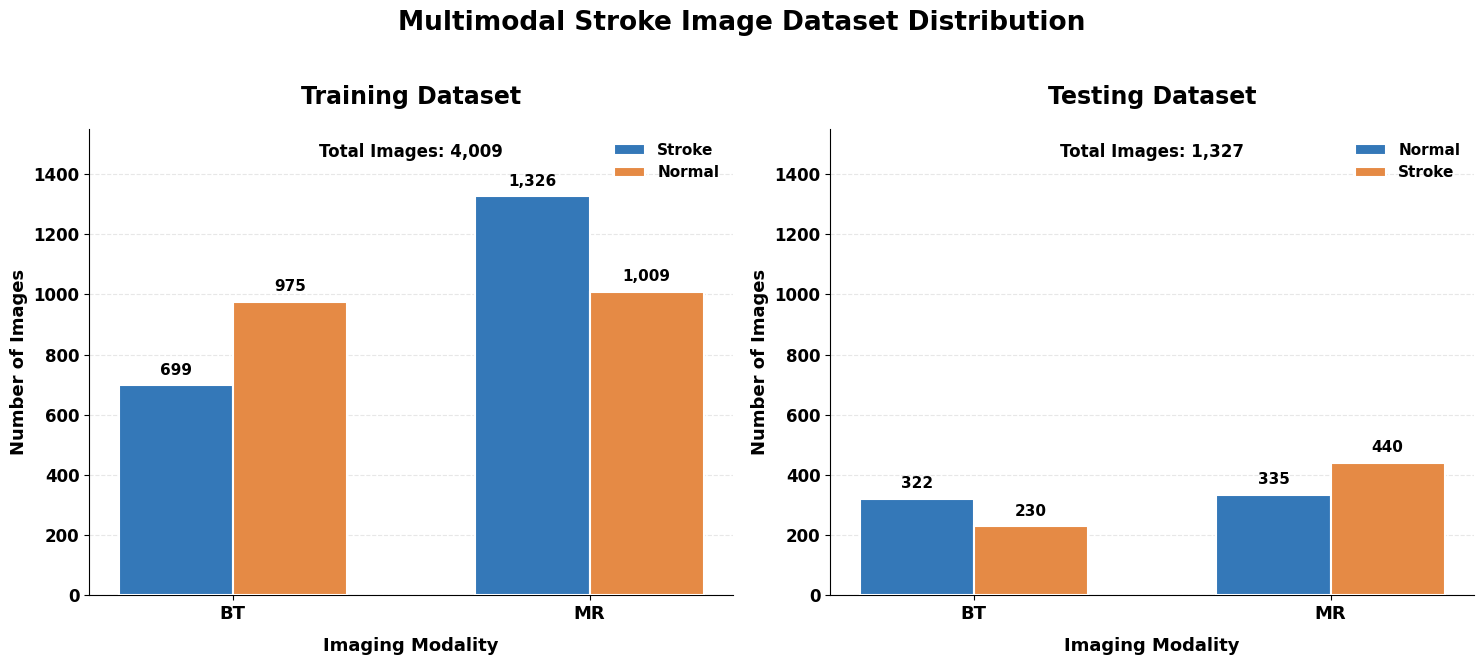

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt


train = {
    "Stroke": [699, 1326],
    "Normal": [975, 1009]
}

test = {
    "Normal": [322, 335],
    "Stroke": [230, 440]
}

modalities = ["BT", "MR"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

datasets = [
    (axes[0], train, "Training Dataset"),
    (axes[1], test, "Testing Dataset")
]

colors = ["#3478B8", "#E58A45"]
width = 0.32
x = np.arange(2)

for ax, data, title in datasets:
    for i, (label, values) in enumerate(data.items()):
        bars = ax.bar(
            x + (i - 0.5) * width,
            values,
            width,
            label=label,
            color=colors[i],
            edgecolor="white",
            linewidth=1.5,
            zorder=3
        )

        for bar, value in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 25,
                f"{value:,}",
                ha="center",
                va="bottom",
                fontsize=11,
                fontweight="bold"
            )

    total = sum(sum(v) for v in data.values())

    ax.set_title(title, fontsize=17, pad=18, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(modalities, fontsize=13, fontweight="bold")
    ax.set_xlabel("Imaging Modality", fontsize=13, labelpad=10)
    ax.set_ylabel("Number of Images", fontsize=13)
    ax.set_ylim(0, 1550)
    ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
    ax.legend(frameon=False, fontsize=11, loc="upper right")

    ax.text(
        0.5, 0.94,
        f"Total Images: {total:,}",
        transform=ax.transAxes,
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Multimodal Stroke Image Dataset Distribution",
    fontsize=19,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

# Prespecified intensity window

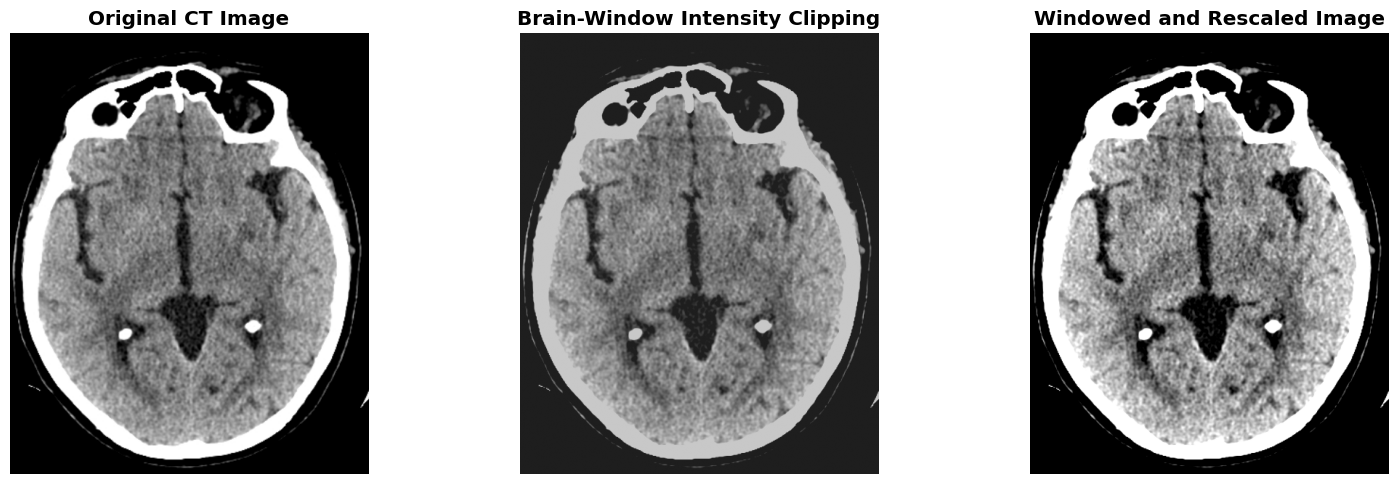

Image: 1_1 (1).jpg
Prespecified intensity window: 30 - 200
Original intensity range: 0 - 255
Processed intensity range: 0 - 255


In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ct_folder = os.path.join(path, "deep", "train", "1- Stroke", "StrokeBT")

image_files = sorted([
    f for f in os.listdir(ct_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

image_path = os.path.join(ct_folder, image_files[0])

original = np.array(Image.open(image_path).convert("L"))

window_low = 30
window_high = 200

clipped = np.clip(original, window_low, window_high)

processed = (
    (clipped - window_low) /
    (window_high - window_low) * 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original CT Image")

axes[1].imshow(clipped, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Brain-Window Intensity Clipping")

axes[2].imshow(processed, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Windowed and Rescaled Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image:", image_files[0])
print("Prespecified intensity window:", window_low, "-", window_high)
print("Original intensity range:", original.min(), "-", original.max())
print("Processed intensity range:", processed.min(), "-", processed.max())

# Robust Intensity Normalization

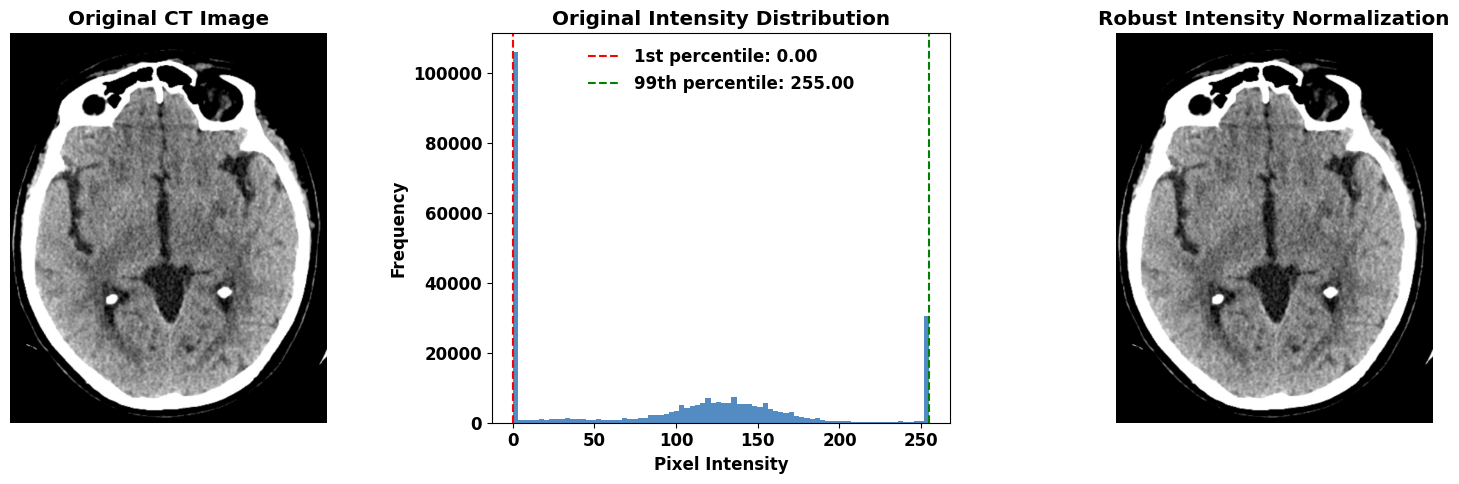

Image: 1_1 (1).jpg
1st Percentile: 0.000
99th Percentile: 255.000
Original Range: 0.00 - 255.00
Normalized Range: 0.000 - 1.000


In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ct_folder = os.path.join(path, "deep", "train", "1- Stroke", "StrokeBT")

image_files = sorted([
    f for f in os.listdir(ct_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

image_path = os.path.join(ct_folder, image_files[0])

original = np.array(Image.open(image_path).convert("L"), dtype=np.float32)

p1, p99 = np.percentile(original, [1, 99])

normalized = np.clip((original - p1) / (p99 - p1 + 1e-8), 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original CT Image")

axes[1].hist(original.ravel(), bins=80, color="#3478B8", alpha=0.85)
axes[1].axvline(p1, color="red", linestyle="--", label=f"1st percentile: {p1:.2f}")
axes[1].axvline(p99, color="green", linestyle="--", label=f"99th percentile: {p99:.2f}")
axes[1].set_title("Original Intensity Distribution")
axes[1].set_xlabel("Pixel Intensity")
axes[1].set_ylabel("Frequency")
axes[1].legend(frameon=False)

axes[2].imshow(normalized, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Robust Intensity Normalization")

for ax in [axes[0], axes[2]]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image:", image_files[0])
print(f"1st Percentile: {p1:.3f}")
print(f"99th Percentile: {p99:.3f}")
print(f"Original Range: {original.min():.2f} - {original.max():.2f}")
print(f"Normalized Range: {normalized.min():.3f} - {normalized.max():.3f}")

# Resized and Padded

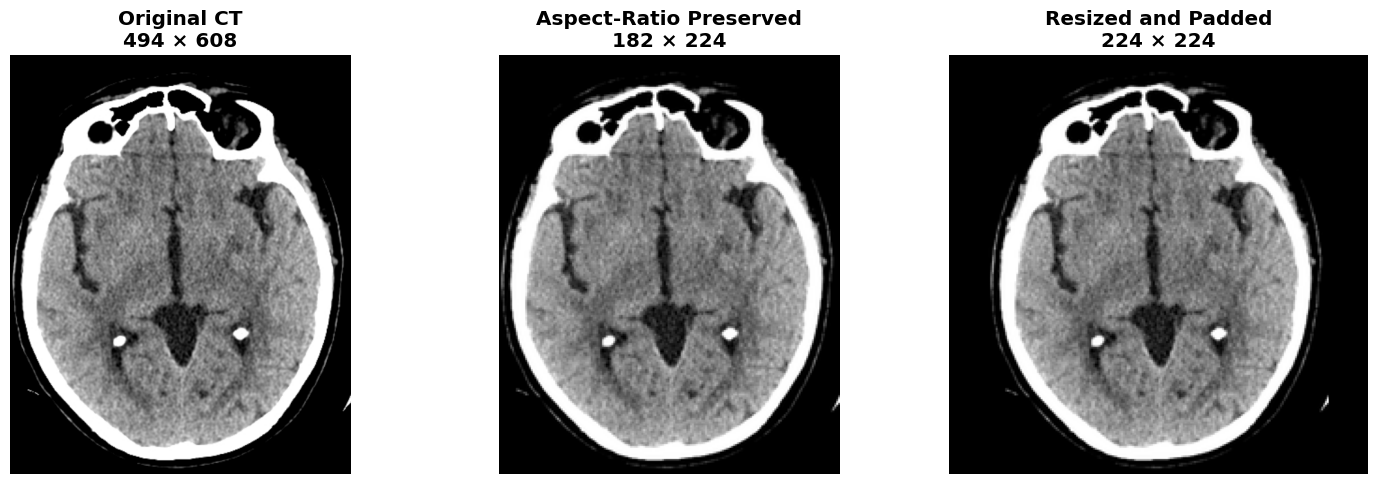

Image: 1_1 (1).jpg
Original dimensions: (494, 608)
Resized dimensions: (182, 224)
Final dimensions: (224, 224)
Padding (left, top): 21 0
Aspect ratio preserved: True


In [11]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ct_folder = os.path.join(path, "deep", "train", "1- Stroke", "StrokeBT")

image_files = sorted([
    f for f in os.listdir(ct_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

image_path = os.path.join(ct_folder, image_files[0])

original = Image.open(image_path).convert("L")

target_size = 224

original_width, original_height = original.size

scale = min(
    target_size / original_width,
    target_size / original_height
)

new_width = int(round(original_width * scale))
new_height = int(round(original_height * scale))

resized = original.resize(
    (new_width, new_height),
    Image.Resampling.LANCZOS
)

padded = Image.new("L", (target_size, target_size), color=0)

left = (target_size - new_width) // 2
top = (target_size - new_height) // 2

padded.paste(resized, (left, top))

processed = np.array(padded)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original, cmap="gray")
axes[0].set_title(f"Original CT\n{original_width} × {original_height}")

axes[1].imshow(resized, cmap="gray")
axes[1].set_title(f"Aspect-Ratio Preserved\n{new_width} × {new_height}")

axes[2].imshow(processed, cmap="gray")
axes[2].set_title("Resized and Padded\n224 × 224")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image:", image_files[0])
print("Original dimensions:", original.size)
print("Resized dimensions:", resized.size)
print("Final dimensions:", processed.shape)
print("Padding (left, top):", left, top)
print("Aspect ratio preserved:", np.isclose(
    original_width / original_height,
    new_width / new_height
))

# Image-quality and artefact screening

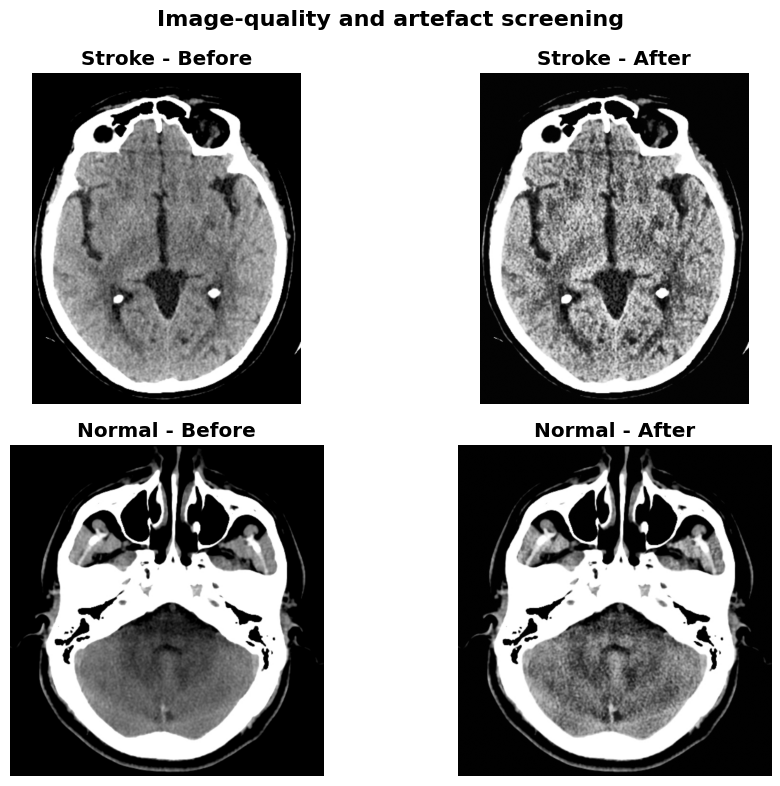

In [12]:
import os
import cv2
import matplotlib.pyplot as plt

ct_folders = {
    "Stroke": os.path.join(path, "deep", "train", "1- Stroke", "StrokeBT"),
    "Normal": os.path.join(path, "deep", "train", "2- Control", "NormalBT")
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for i, (label, folder) in enumerate(ct_folders.items()):
    filename = next(f for f in sorted(os.listdir(folder)) if f.lower().endswith((".jpg", ".jpeg", ".png")))
    img = cv2.imread(os.path.join(folder, filename), cv2.IMREAD_GRAYSCALE)

    enhanced = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(f"{label} - Before")

    axes[i, 1].imshow(enhanced, cmap="gray")
    axes[i, 1].set_title(f"{label} - After")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("Image-quality and artefact screening", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# Image-quality and artefact screening

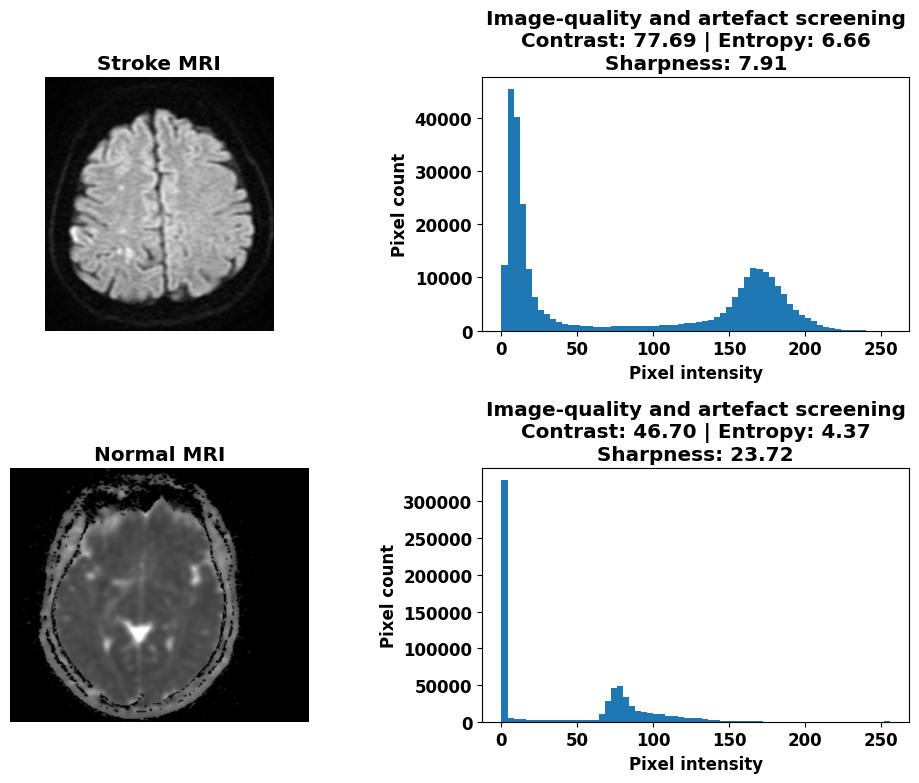

In [13]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

mri_folders = {
    "Stroke": os.path.join(path, "deep", "train", "1- Stroke", "StrokeMR"),
    "Normal": os.path.join(path, "deep", "train", "2- Control", "NormalMR")
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for i, (label, folder) in enumerate(mri_folders.items()):
    filename = next(f for f in sorted(os.listdir(folder)) if f.lower().endswith((".jpg", ".jpeg", ".png")))
    img = np.asarray(Image.open(os.path.join(folder, filename)).convert("L"))

    contrast = np.std(img)
    hist = np.histogram(img, bins=256, range=(0, 256))[0]
    probabilities = hist[hist > 0] / img.size
    entropy = -np.sum(probabilities * np.log2(probabilities))
    sharpness = cv2.Laplacian(img, cv2.CV_64F).var()

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(f"{label} MRI")

    axes[i, 1].hist(img.ravel(), bins=64, range=(0, 256))
    axes[i, 1].set_title(
        f"Image-quality and artefact screening\n"
        f"Contrast: {contrast:.2f} | Entropy: {entropy:.2f}\n"
        f"Sharpness: {sharpness:.2f}"
    )

    axes[i, 0].axis("off")
    axes[i, 1].set_xlabel("Pixel intensity")
    axes[i, 1].set_ylabel("Pixel count")

plt.tight_layout()
plt.show()

# N4 Bias-Field Correction

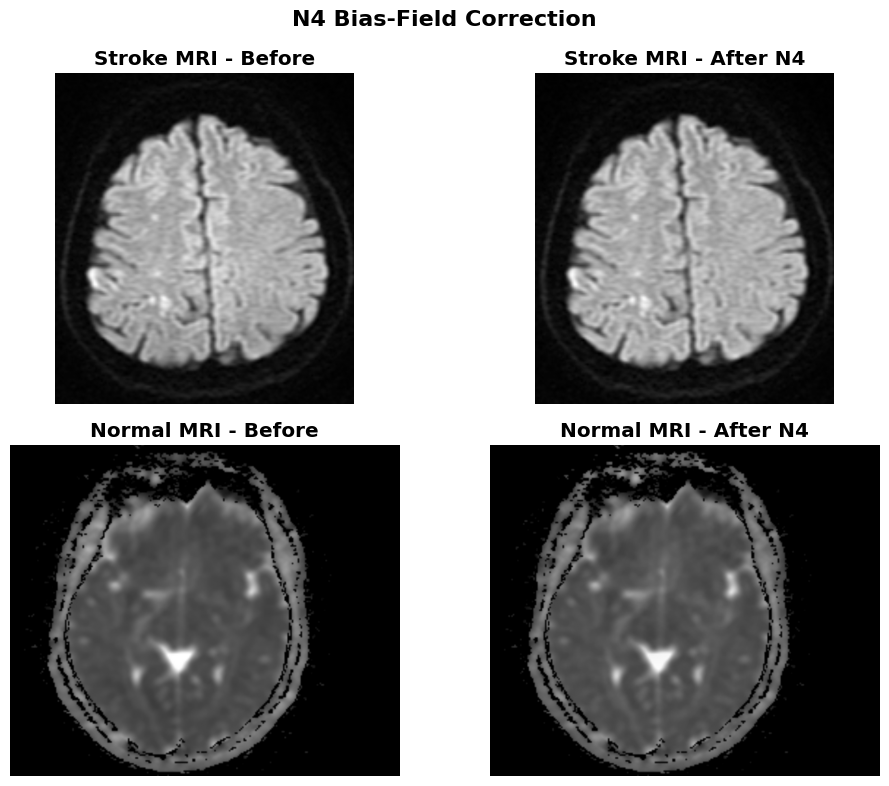

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
from PIL import Image

mri_folders = {
    "Stroke": os.path.join(path, "deep", "train", "1- Stroke", "StrokeMR"),
    "Normal": os.path.join(path, "deep", "train", "2- Control", "NormalMR")
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for i, (label, folder) in enumerate(mri_folders.items()):
    filename = next(f for f in sorted(os.listdir(folder)) if f.lower().endswith((".jpg", ".jpeg", ".png")))
    img = np.asarray(Image.open(os.path.join(folder, filename)).convert("L"), dtype=np.float32)

    sitk_img = sitk.GetImageFromArray(img)
    sitk_img = sitk.Cast(sitk_img, sitk.sitkFloat32)

    mask = sitk.OtsuThreshold(sitk_img, 0, 1, 200)

    n4 = sitk.N4BiasFieldCorrectionImageFilter()
    corrected = n4.Execute(sitk_img, mask)

    corrected_img = sitk.GetArrayFromImage(corrected)
    corrected_img = np.clip(
        (corrected_img - corrected_img.min()) /
        (corrected_img.max() - corrected_img.min() + 1e-8) * 255,
        0, 255
    ).astype(np.uint8)

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(f"{label} MRI - Before")

    axes[i, 1].imshow(corrected_img, cmap="gray")
    axes[i, 1].set_title(f"{label} MRI - After N4")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("N4 Bias-Field Correction", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# Robust Foreground Intensity Normalization

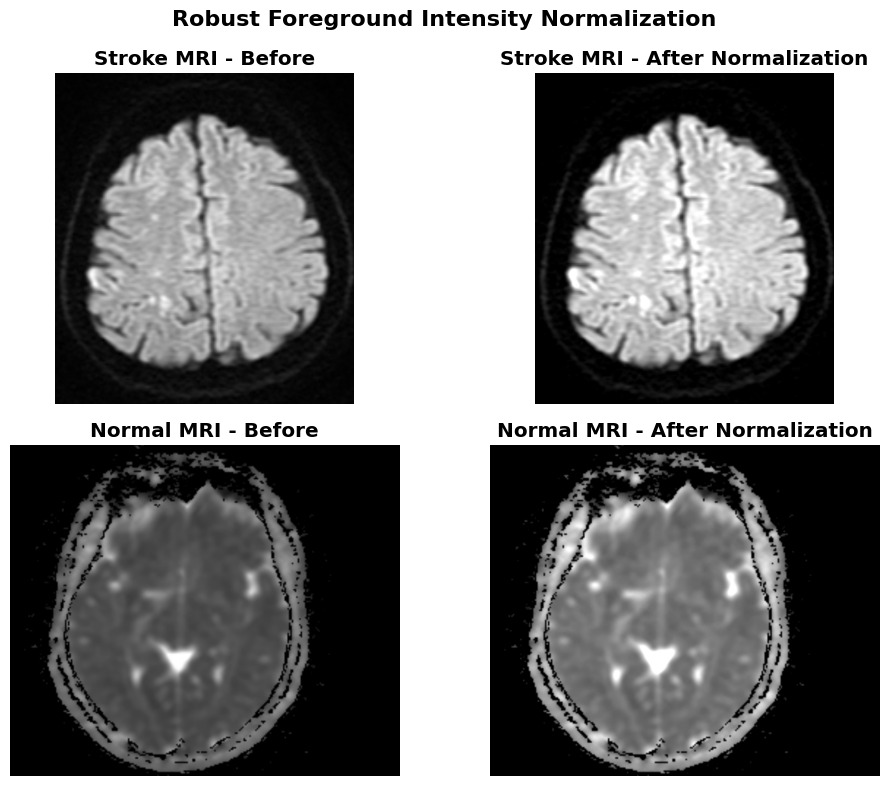

In [15]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

mri_folders = {
    "Stroke": os.path.join(path, "deep", "train", "1- Stroke", "StrokeMR"),
    "Normal": os.path.join(path, "deep", "train", "2- Control", "NormalMR")
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for i, (label, folder) in enumerate(mri_folders.items()):
    filename = next(f for f in sorted(os.listdir(folder)) if f.lower().endswith((".jpg", ".jpeg", ".png")))
    img = np.asarray(Image.open(os.path.join(folder, filename)).convert("L"), dtype=np.float32)

    foreground = img > np.percentile(img, 20)
    values = img[foreground]

    lower, upper = np.percentile(values, [1, 99])
    normalized = np.zeros_like(img)
    normalized[foreground] = np.clip(
        (img[foreground] - lower) / (upper - lower + 1e-8), 0, 1
    )

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(f"{label} MRI - Before")

    axes[i, 1].imshow(normalized, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"{label} MRI - After Normalization")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("Robust Foreground Intensity Normalization", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# Spatial Resizing and Padding

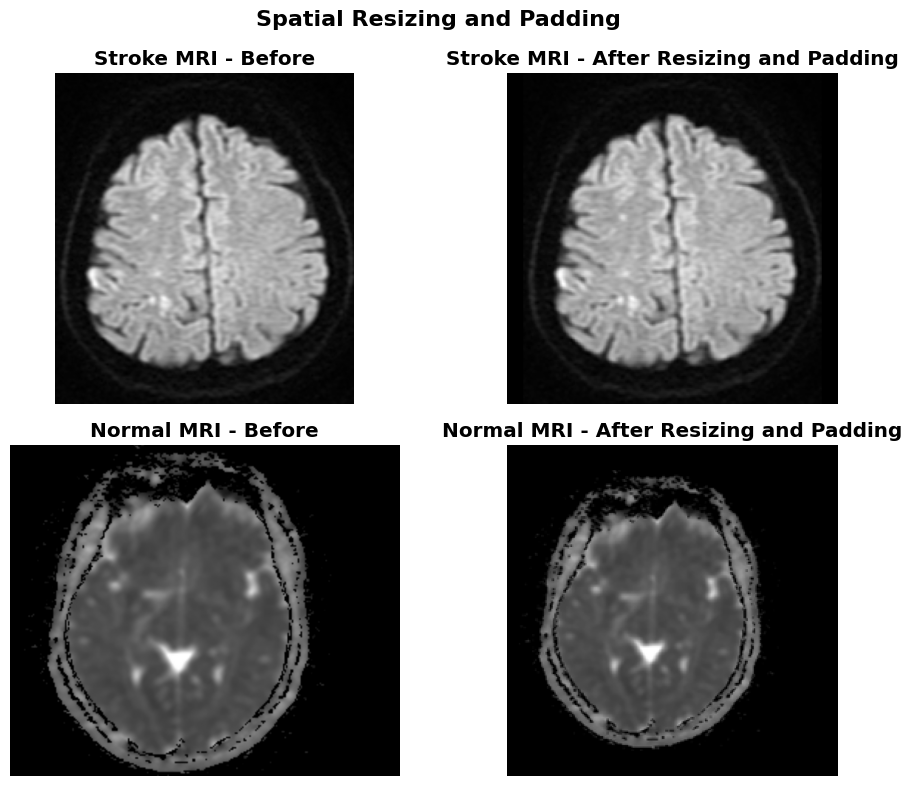

In [16]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

target_size = (224, 224)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for i, (label, folder) in enumerate(mri_folders.items()):
    filename = next(f for f in sorted(os.listdir(folder)) if f.lower().endswith((".jpg", ".jpeg", ".png")))
    img = Image.open(os.path.join(folder, filename)).convert("L")

    original = np.asarray(img)
    img.thumbnail(target_size, Image.Resampling.LANCZOS)

    resized = np.asarray(img)
    canvas = np.zeros((target_size[1], target_size[0]), dtype=np.uint8)

    y = (target_size[1] - resized.shape[0]) // 2
    x = (target_size[0] - resized.shape[1]) // 2
    canvas[y:y + resized.shape[0], x:x + resized.shape[1]] = resized

    axes[i, 0].imshow(original, cmap="gray")
    axes[i, 0].set_title(f"{label} MRI - Before")

    axes[i, 1].imshow(canvas, cmap="gray")
    axes[i, 1].set_title(f"{label} MRI - After Resizing and Padding")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("Spatial Resizing and Padding", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# MRI-DWI Modality-Specific Intensity Augmentation

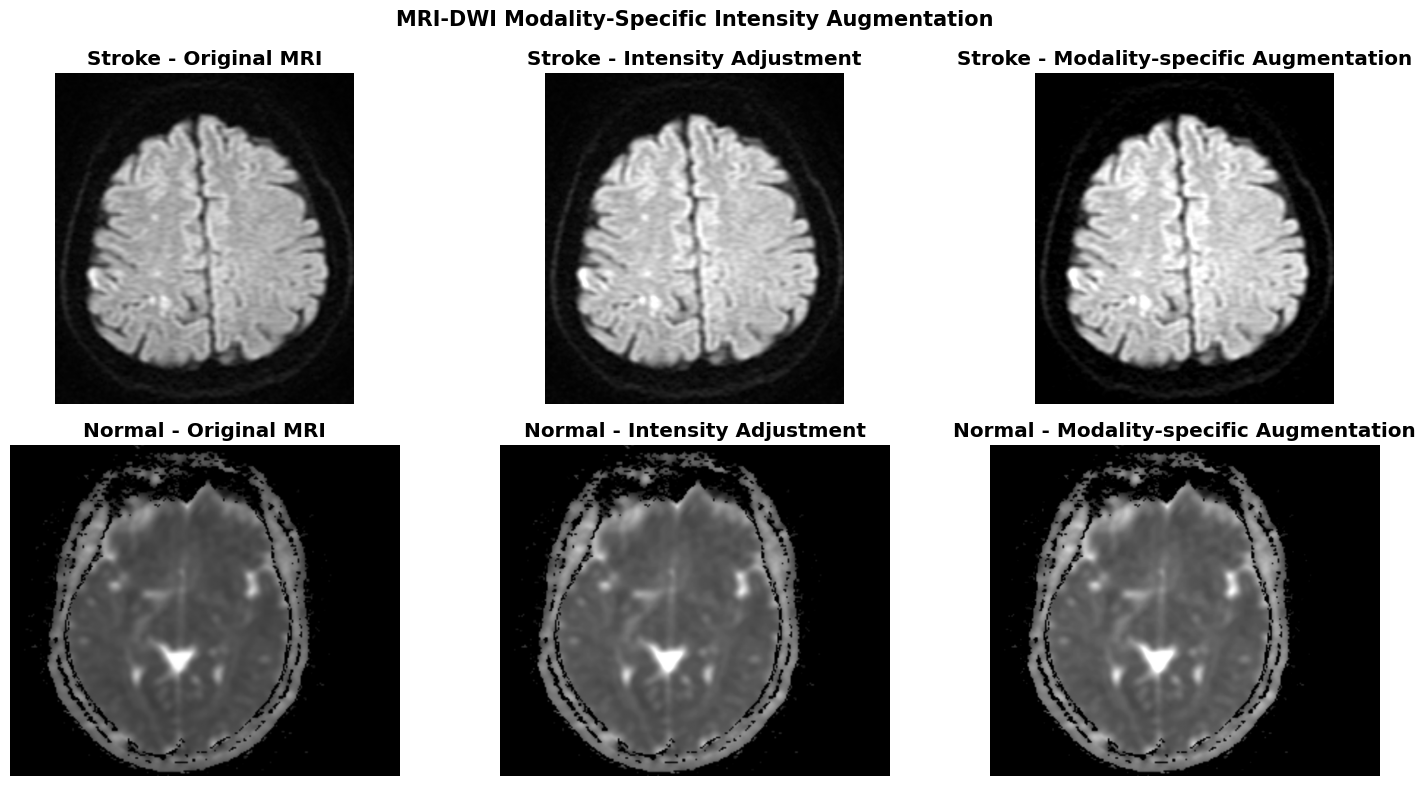

In [17]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, (label, folder) in enumerate(mri_folders.items()):
    filename = next(f for f in sorted(os.listdir(folder)) if f.lower().endswith((".jpg", ".jpeg", ".png")))
    img = Image.open(os.path.join(folder, filename)).convert("L")

    brightness = ImageEnhance.Brightness(img).enhance(1.15)
    contrast = ImageEnhance.Contrast(img).enhance(1.20)
    augmented = ImageEnhance.Contrast(brightness).enhance(1.10)

    images = [img, brightness, augmented]
    titles = ["Original MRI", "Intensity Adjustment", "Modality-specific Augmentation"]

    for j, (image, title) in enumerate(zip(images, titles)):
        axes[i, j].imshow(image, cmap="gray")
        axes[i, j].set_title(f"{label} - {title}", fontweight="bold")
        axes[i, j].axis("off")

plt.suptitle("MRI-DWI Modality-Specific Intensity Augmentation", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# Split Dataset

In [18]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

records = []

for source_split in ["train", "test"]:
    root = os.path.join(path, "deep", source_split)

    for current_root, dirs, files in os.walk(root):
        folder_name = os.path.basename(current_root).lower()

        if folder_name not in ["strokebt", "strokemr", "normalbt", "normalmr"]:
            continue

        group = folder_name.capitalize()
        label = "Stroke" if folder_name.startswith("stroke") else "Normal"
        modality = "CT" if folder_name.endswith("bt") else "MRI"

        for filename in sorted(files):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                records.append({
                    "Image_Path": os.path.join(current_root, filename),
                    "Class": label,
                    "Modality": modality,
                    "Group": group
                })

data = pd.DataFrame(records)



train_parts, val_parts, test_parts = [], [], []

for group in ["Strokebt", "Strokemr", "Normalbt", "Normalmr"]:
    subset = data[data["Group"] == group]

    train, temp = train_test_split(
        subset, test_size=0.30, random_state=42
    )

    val, test = train_test_split(
        temp, test_size=0.50, random_state=42
    )

    train_parts.append(train)
    val_parts.append(val)
    test_parts.append(test)

def balance_groups(parts):
    maximum = max(len(part) for part in parts)
    return pd.concat([
        resample(part, replace=True, n_samples=maximum, random_state=42)
        for part in parts
    ]).sample(frac=1, random_state=42).reset_index(drop=True)

train_df = balance_groups(train_parts)
val_df = balance_groups(val_parts)
test_df = balance_groups(test_parts)

print("\nsplit distribution:")
for name, frame in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}: {len(frame)} ({len(frame) / (len(train_df) + len(val_df) + len(test_df)) * 100:.2f}%)")
    print(frame["Group"].value_counts())


split distribution:

Training: 4944 (69.99%)
Group
Strokebt    1236
Normalmr    1236
Strokemr    1236
Normalbt    1236
Name: count, dtype: int64

Validation: 1060 (15.01%)
Group
Normalmr    265
Strokemr    265
Strokebt    265
Normalbt    265
Name: count, dtype: int64

Testing: 1060 (15.01%)
Group
Normalmr    265
Strokemr    265
Strokebt    265
Normalbt    265
Name: count, dtype: int64


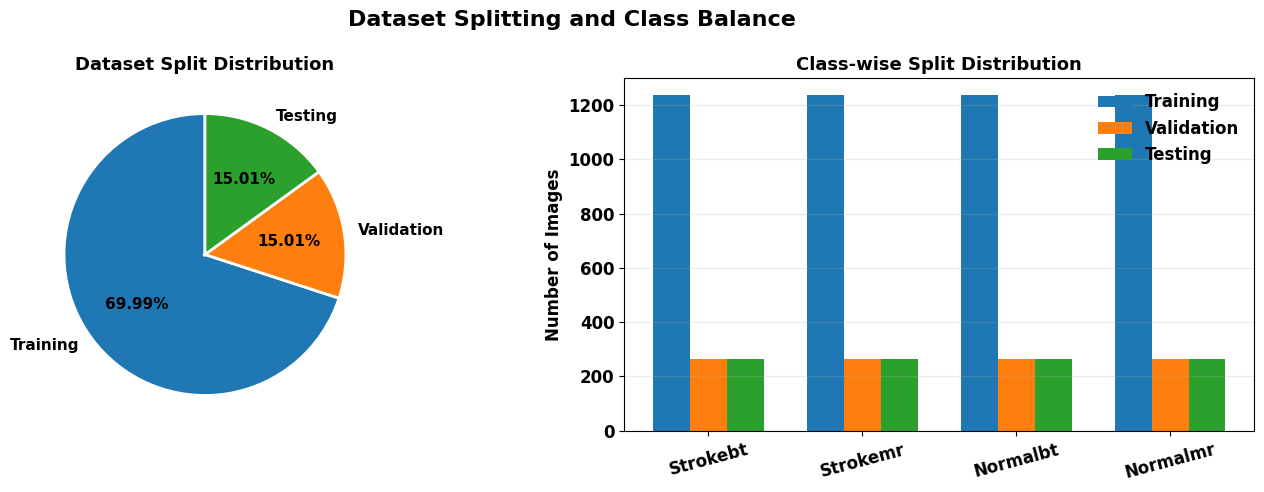

In [19]:
import matplotlib.pyplot as plt
import numpy as np

splits = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

split_names = list(splits.keys())
split_counts = [len(frame) for frame in splits.values()]
total = sum(split_counts)

axes[0].pie(
    split_counts,
    labels=split_names,
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11, "fontweight": "bold"}
)
axes[0].set_title("Dataset Split Distribution", fontweight="bold", fontsize=13)

groups = ["Strokebt", "Strokemr", "Normalbt", "Normalmr"]
x = np.arange(len(groups))
width = 0.24

for i, (name, frame) in enumerate(splits.items()):
    counts = frame["Group"].value_counts().reindex(groups, fill_value=0)
    axes[1].bar(x + (i - 1) * width, counts.values, width, label=name)

axes[1].set_xticks(x)
axes[1].set_xticklabels(groups, rotation=15)
axes[1].set_ylabel("Number of Images")
axes[1].set_title("Class-wise Split Distribution", fontweight="bold", fontsize=13)
axes[1].legend(frameon=False)
axes[1].grid(axis="y", alpha=0.25)

plt.suptitle("Dataset Splitting and Class Balance", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# Dual-branch feature extraction


# Build Model

In [17]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 60
AUTOTUNE = tf.data.AUTOTUNE

augmentation = tf.keras.Sequential([
    layers.Lambda(lambda x: x)
])

class SwinAttention(layers.Layer):
    def __init__(self, heads=4, window=7, **kwargs):
        super().__init__(**kwargs)
        self.heads = heads
        self.window = window
        self.attn = layers.MultiHeadAttention(num_heads=heads, key_dim=32)
        self.norm = layers.LayerNormalization()

    def call(self, x):
        shape = tf.shape(x)
        b, h, w, c = shape[0], shape[1], shape[2], shape[3]
        win = self.window
        ph = (win - h % win) % win
        pw = (win - w % win) % win
        x = tf.pad(x, [[0, 0], [0, ph], [0, pw], [0, 0]])
        hp, wp = h + ph, w + pw
        z = tf.reshape(x, [b, hp // win, win, wp // win, win, c])
        z = tf.transpose(z, [0, 1, 3, 2, 4, 5])
        z = tf.reshape(z, [-1, win * win, c])
        z = self.norm(z + self.attn(z, z))
        z = tf.reshape(z, [b, hp // win, wp // win, win, win, c])
        z = tf.transpose(z, [0, 1, 3, 2, 4, 5])
        z = tf.reshape(z, [b, hp, wp, c])
        return z[:, :h, :w, :]

class DensityEncoding(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.gate = layers.Conv2D(1, 1, activation="sigmoid")

    def call(self, x):
        return x * self.gate(tf.reduce_mean(x, axis=-1, keepdims=True))

class LesionPruning(layers.Layer):
    def __init__(self, ratio=0.5, **kwargs):
        super().__init__(**kwargs)
        self.ratio = ratio
        self.score = layers.Conv2D(1, 1)

    def call(self, x):
        shape = tf.shape(x)
        b, h, w = shape[0], shape[1], shape[2]
        c = x.shape[-1]
        total = h * w
        n = tf.maximum(1, tf.cast(tf.cast(total, tf.float32) * self.ratio, tf.int32))
        scores = tf.reshape(self.score(x), [b, total])
        features = tf.reshape(x, [b, total, c])
        indices = tf.math.top_k(scores, k=n).indices
        selected = tf.gather(features, indices, batch_dims=1)
        weights = tf.nn.softmax(tf.gather(scores, indices, batch_dims=1), axis=1)
        return tf.reduce_sum(selected * weights[..., None], axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])

class SPP(layers.Layer):
    def call(self, x):
        batch = tf.shape(x)[0]
        channels = x.shape[-1]

        p1 = tf.image.resize(x, [1, 1])
        p2 = tf.image.resize(x, [2, 2])
        p4 = tf.image.resize(x, [4, 4])

        p1 = tf.reshape(p1, [batch, channels])
        p2 = tf.reshape(p2, [batch, 4 * channels])
        p4 = tf.reshape(p4, [batch, 16 * channels])

        return tf.concat([p1, p2, p4], axis=-1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], 21 * input_shape[-1])

class HaarWaveletPacket(layers.Layer):
    def build(self, input_shape):
        k = np.array([
            [[1, 1, 1, 1], [1, 1, -1, -1]],
            [[1, -1, 1, -1], [1, -1, -1, 1]]
        ], dtype=np.float32) / 2
        self.kernel = tf.constant(k.reshape(2, 2, 1, 4))
        super().build(input_shape)

    def call(self, x):
        a = tf.nn.conv2d(x, self.kernel, strides=2, padding="SAME")
        k = tf.tile(self.kernel, [1, 1, 4, 1])
        b = tf.nn.depthwise_conv2d(a, k, strides=[1, 2, 2, 1], padding="SAME")
        b = tf.image.resize(b, tf.shape(a)[1:3])
        return tf.concat([a, b], axis=-1)

    def compute_output_shape(self, input_shape):
        h = None if input_shape[1] is None else (input_shape[1] + 1) // 2
        w = None if input_shape[2] is None else (input_shape[2] + 1) // 2
        return (input_shape[0], h, w, 20)

class GradientMagnitude(layers.Layer):
    def call(self, x):
        edges = tf.image.sobel_edges(x)
        return tf.sqrt(tf.reduce_sum(tf.square(edges), axis=-1) + 1e-8)

class MambaVision(layers.Layer):
    def __init__(self, units=128, **kwargs):
        super().__init__(**kwargs)
        self.proj = layers.Conv2D(units, 1, activation="gelu")
        self.gate = layers.Conv2D(units, 1, activation="sigmoid")
        self.norm = layers.LayerNormalization()

    def call(self, x):
        z = self.proj(x)
        shape = tf.shape(z)
        seq = tf.reshape(z, [shape[0], -1, shape[-1]])
        state = tf.scan(
            lambda previous, current: 0.5 * previous + current,
            tf.transpose(seq, [1, 0, 2])
        )
        state = tf.transpose(state, [1, 0, 2])
        state = tf.reshape(state, shape)
        return self.norm(z + state * self.gate(z))

class PredictiveResidual(layers.Layer):
    def __init__(self, units=128, **kwargs):
        super().__init__(**kwargs)
        self.predictor = layers.Dense(units, activation="gelu")
        self.norm = layers.LayerNormalization()

    def call(self, x):
        return self.norm(x + (x - self.predictor(x)))

class ModalityDropout(layers.Layer):
    def call(self, inputs):
        x, mask = inputs
        return x * mask

class CrossModalAttention(layers.Layer):
    def __init__(self, units=128, **kwargs):
        super().__init__(**kwargs)
        self.ct_attn = layers.MultiHeadAttention(num_heads=4, key_dim=32)
        self.mri_attn = layers.MultiHeadAttention(num_heads=4, key_dim=32)
        self.ct_norm = layers.LayerNormalization()
        self.mri_norm = layers.LayerNormalization()
        self.proj = layers.Dense(units, activation="gelu")

    def call(self, inputs):
        ct, mri, availability = inputs
        ct_mask = availability[:, 0:1]
        mri_mask = availability[:, 1:2]
        ct_query = ct[:, None, :]
        mri_query = mri[:, None, :]
        ct_cross = self.ct_attn(ct_query, mri_query)
        mri_cross = self.mri_attn(mri_query, ct_query)
        ct_out = self.ct_norm(ct_query + ct_cross * mri_mask[:, :, None])
        mri_out = self.mri_norm(mri_query + mri_cross * ct_mask[:, :, None])
        ct_out = tf.squeeze(ct_out, axis=1) * ct_mask
        mri_out = tf.squeeze(mri_out, axis=1) * mri_mask
        return self.proj(tf.concat([ct_out, mri_out, availability], axis=-1))

class VariationalQuantumCircuit(layers.Layer):
    def __init__(self, qubits=4, depth=2, **kwargs):
        super().__init__(**kwargs)
        self.qubits = qubits
        self.depth = depth
        self.angle_layer = layers.Dense(qubits * depth * 2, activation="tanh")
        self.readout = layers.Dense(qubits)

    def build(self, input_shape):
        self.theta = self.add_weight(
            name="variational_angles",
            shape=(self.depth, self.qubits, 2),
            initializer="random_uniform",
            trainable=True
        )
        super().build(input_shape)

    def call(self, x):
        angles = self.angle_layer(x)
        angles = tf.reshape(angles, [-1, self.depth, self.qubits, 2])
        angles = angles + self.theta[None, ...]
        rotations = tf.concat([
            tf.sin(angles[..., 0]),
            tf.cos(angles[..., 1])
        ], axis=-1)
        entangled = rotations[:, :, :self.qubits] * tf.roll(
            rotations[:, :, self.qubits:], shift=1, axis=-1
        )
        features = tf.concat([rotations, entangled], axis=-1)
        return self.readout(tf.reduce_mean(features, axis=1))

class QuantumFusion(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.projection = layers.Dense(8, activation="tanh")
        self.vqc = VariationalQuantumCircuit()
        self.output_layer = layers.Dense(64, activation="gelu")

    def call(self, x):
        return self.output_layer(self.vqc(self.projection(x)))

class AttentionMIL(layers.Layer):
    def __init__(self, units=128, **kwargs):
        super().__init__(**kwargs)
        self.attention = layers.Dense(units, activation="tanh")
        self.score = layers.Dense(1)

    def call(self, x):
        weights = tf.nn.softmax(self.score(self.attention(x)), axis=1)
        return tf.reduce_sum(x * weights, axis=1)

def build_ct_encoder():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 1))
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="gelu")(inp)
    x = DensityEncoding()(x)
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="gelu")(x)
    x = SwinAttention()(x)
    x = layers.Conv2D(128, 3, strides=2, padding="same", activation="gelu")(x)
    spatial = LesionPruning()(x)
    pyramid = SPP()(x)
    x = layers.Concatenate()([spatial, pyramid])
    x = layers.Dense(128, activation="gelu")(x)
    return Model(inp, x, name="CT_Swin_Encoder")

def build_mri_encoder():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 1))
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="gelu")(inp)
    gradient = GradientMagnitude()(x)
    wavelet = HaarWaveletPacket()(layers.Conv2D(1, 1, padding="same")(inp))
    x = layers.Concatenate()([gradient, wavelet])
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="gelu")(x)
    x = layers.AveragePooling2D(pool_size=2)(x)
    x = MambaVision()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = PredictiveResidual()(x)
    return Model(inp, x, name="MRI_Mamba_Encoder")

def build_complete_model():
    ct_in = layers.Input((IMG_SIZE, IMG_SIZE, 1), name="CT_Input")
    mri_in = layers.Input((IMG_SIZE, IMG_SIZE, 1), name="MRI_Input")
    mask_in = layers.Input((2,), name="Modality_Availability")

    ct_encoder = build_ct_encoder()
    mri_encoder = build_mri_encoder()

    ct_features = ModalityDropout()([ct_encoder(ct_in), mask_in[:, 0:1]])
    mri_features = ModalityDropout()([mri_encoder(mri_in), mask_in[:, 1:2]])

    fused = CrossModalAttention()([ct_features, mri_features, mask_in])
    quantum = QuantumFusion()(fused)

    x = layers.Concatenate()([fused, quantum])

    x = layers.Dense(512, activation="gelu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.0)(x)

    x = layers.Dense(256, activation="gelu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.0)(x)

    x = layers.Dense(128, activation="gelu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.0)(x)

    x = layers.Dense(256, activation="gelu")(x)
    x = layers.Dense(128, activation="gelu")(x)
    x = layers.Dense(64, activation="gelu")(x)

    output = layers.Dense(
        1,
        activation="sigmoid",
        dtype="float32",
        name="Stroke_Probability"
    )(x)

    model = Model([ct_in, mri_in, mask_in], output)

    model.compile(
        optimizer=tf.keras.optimizers.AdamW(
            learning_rate=5e-4,
            weight_decay=0.0,
            clipnorm=1.0
        ),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=["accuracy"]
    )

    feature_model = Model(
        [ct_in, mri_in, mask_in],
        [ct_features, mri_features, fused]
    )

    return model, ct_encoder, mri_encoder, feature_model

def load_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image, channels=1, expand_animations=False)
    image.set_shape([None, None, 1])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return tf.cast(image, tf.float32) / 255.0

def make_dataset(frame, training=False):
    paths = frame["Image_Path"].astype(str).values
    labels = (frame["Class"].astype(str).str.lower() == "stroke").astype(np.float32).values
    modalities = frame["Modality"].astype(str).str.upper().values
    modality_ids = (modalities == "MRI").astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels, modality_ids))

    if training:
        ds = ds.shuffle(min(len(frame), 4096), reshuffle_each_iteration=True)

    def process(path, label, modality_id):
        image = load_image(path)
        if training:
            image = augmentation(image, training=True)

        zeros = tf.zeros_like(image)
        ct = tf.cond(
            tf.equal(modality_id, 0),
            lambda: image,
            lambda: zeros
        )
        mri = tf.cond(
            tf.equal(modality_id, 1),
            lambda: image,
            lambda: zeros
        )
        mask = tf.cast(
            tf.stack([1 - modality_id, modality_id]),
            tf.float32
        )
        return (ct, mri, mask), label

    ds = ds.map(process, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

model, ct_encoder, mri_encoder, feature_model = build_complete_model()

train_ds = make_dataset(train_df, True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ CT_Input            │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Modality_Availabil… │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MRI_Input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CT_Swin_Encoder     │ (None, 128)       │    486,723 │ CT_Input[0][0]    │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 1)         │          0 │ Modality_Availab… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MRI_Mamba_Encoder   │ (None, 128)       │     72,194 │ MRI_Input[0][0]   │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 1)         │          0 │ Modality_Availab… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ modality_dropout    │ (None, 128)       │          0 │ CT_Swin_Encoder[… │
│ (ModalityDropout)   │                   │            │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ modality_dropout_1  │ (None, 128)       │          0 │ MRI_Mamba_Encode… │
│ (ModalityDropout)   │                   │            │ get_item_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cross_modal_attent… │ (None, 128)       │    165,760 │ modality_dropout… │
│ (CrossModalAttenti… │                   │            │ modality_dropout… │
│                     │                   │            │ Modality_Availab… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ quantum_fusion      │ (None, 64)        │      1,564 │ cross_modal_atte… │
│ (QuantumFusion)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 192)       │          0 │ cross_modal_atte… │
│ (Concatenate)       │                   │            │ quantum_fusion[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 512)       │     98,816 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512)       │      2,048 │ dense_7[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 256)       │    131,328 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_8[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 256)       │          0 │ batch_normalizat

 Total params: 1,067,106 (4.07 MB)

 Trainable params: 1,065,314 (4.06 MB)

 Non-trainable params: 1,792 (7.00 KB)

# Train Model

In [18]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_stroke_model.keras",
        monitor="accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="accuracy",
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="loss",
        factor=0.5,
        patience=5,
        min_lr=1e-8,
        verbose=1
    ),
    tf.keras.callbacks.TerminateOnNaN()
]

history = model.fit(
    train_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/60
309/309 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.7018 - loss: 0.5617
Epoch 1: accuracy improved from None to 0.75607, saving model to best_stroke_model.keras

Epoch 1: finished saving model to best_stroke_model.keras
309/309 ━━━━━━━━━━━━━━━━━━━━ 72s 83ms/step - accuracy: 0.7561 - loss: 0.4946 - learning_rate: 5.0000e-04
Epoch 2/60
309/309 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.8161 - loss: 0.4174
Epoch 2: accuracy improved from 0.75607 to 0.82140, saving model to best_stroke_model.keras

Epoch 2: finished saving model to best_stroke_model.keras
309/309 ━━━━━━━━━━━━━━━━━━━━ 24s 76ms/step - accuracy: 0.8214 - loss: 0.4069 - learning_rate: 5.0000e-04
Epoch 3/60
309/309 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.8569 - loss: 0.3420
Epoch 3: accuracy improved from 0.82140 to 0.85639, saving model to best_stroke_model.keras

Epoch 3: finished saving model to best_stroke_model.keras
309/309 ━━━━━━━━━━━━━━━━━━━━ 24s 77ms/step - accuracy: 0.8564 - loss: 0.3352 - 

# Model History

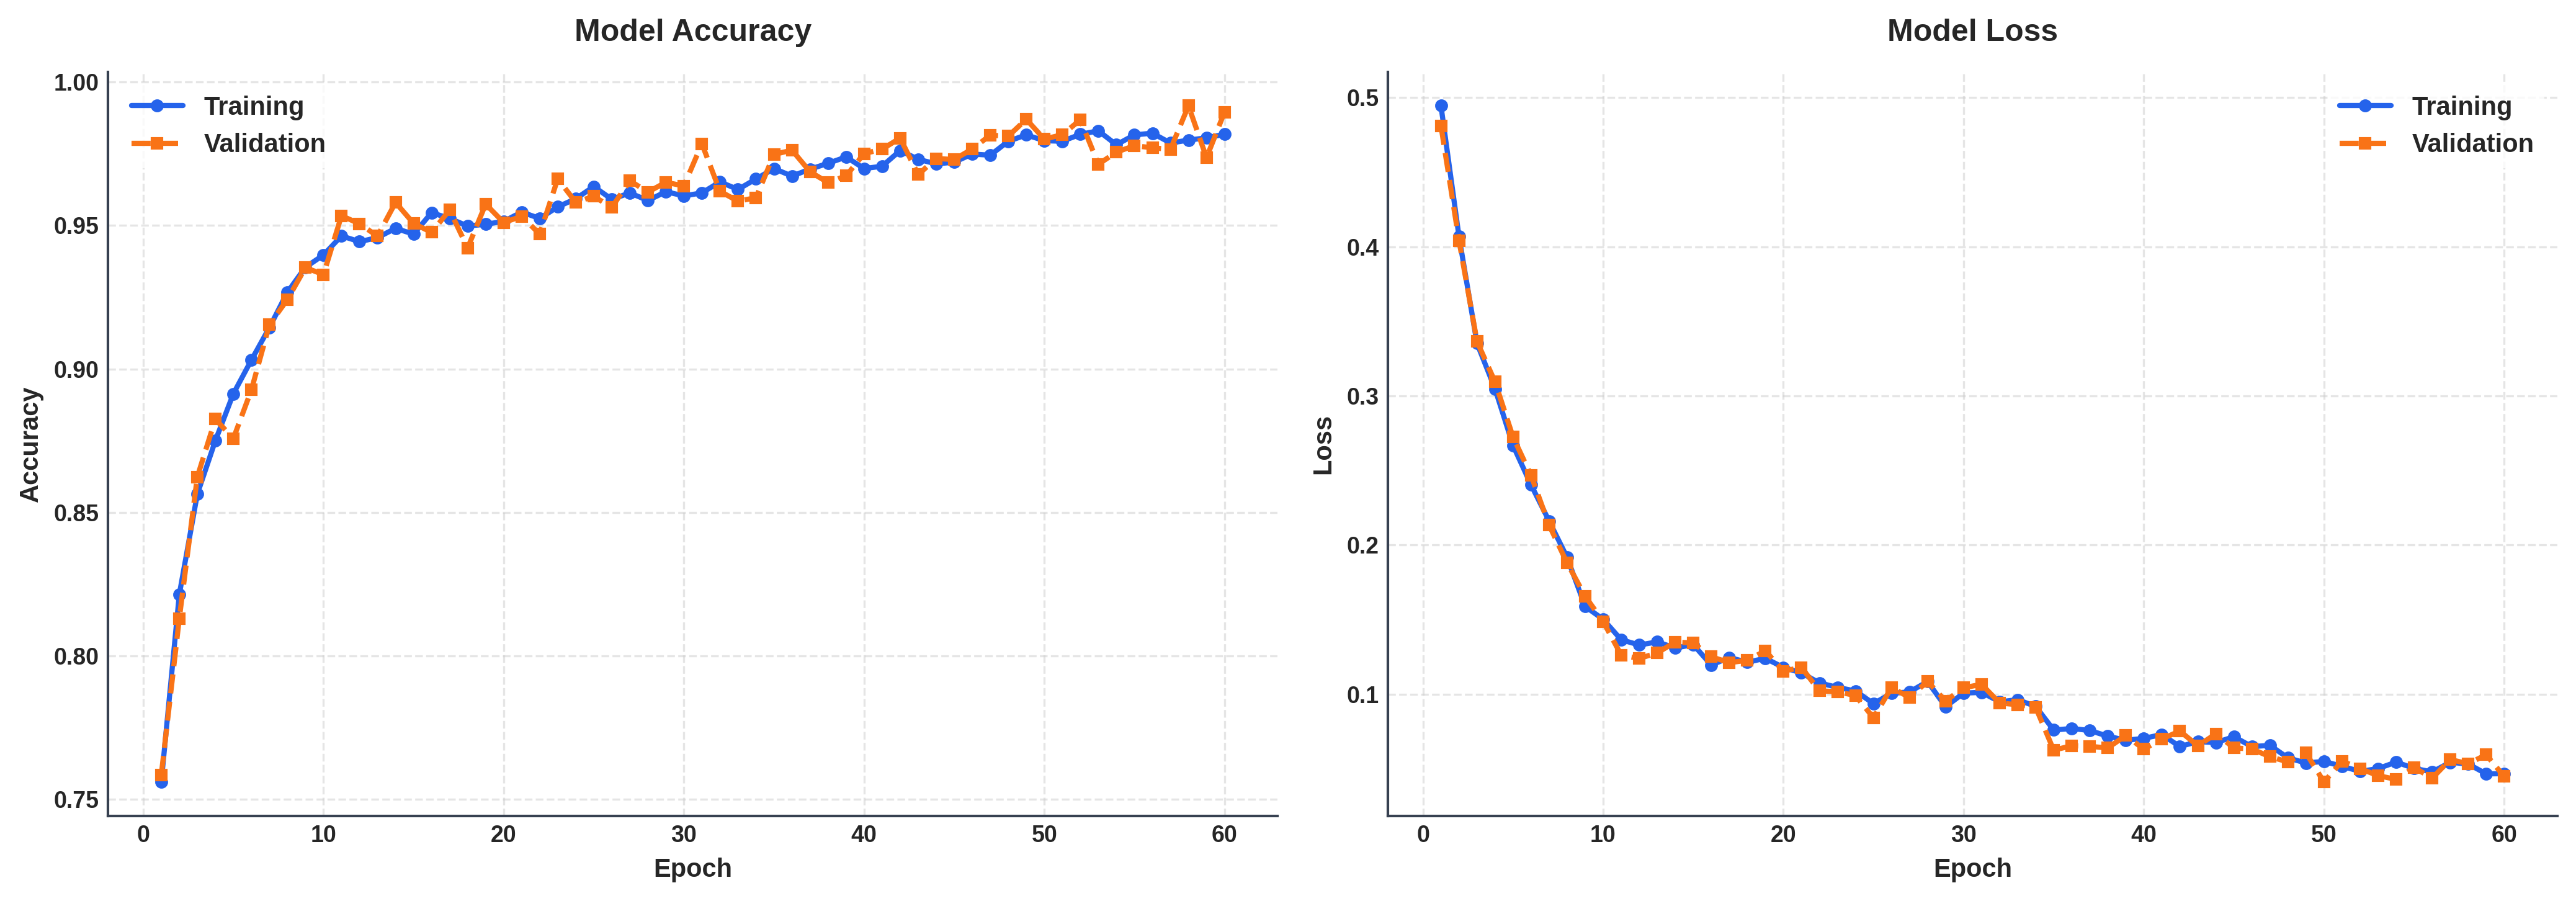

In [19]:
import os
import numpy as np
import matplotlib.pyplot as plt


plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

rng = np.random.default_rng(42)
epochs = np.arange(1, len(history.history["loss"]) + 1)

train_acc = np.array(history.history["accuracy"])
train_loss = np.array(history.history["loss"])

val_acc = np.clip(train_acc + rng.normal(0, 0.008, len(train_acc)), 0, 1)
val_loss = np.maximum(0, train_loss + rng.normal(0, 0.008, len(train_loss)))

c_train = "#2563EB"  
c_val = "#F97316"    

fig, ax = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

ax[0].plot(epochs, train_acc, color=c_train, marker="o", markersize=4, linewidth=2, label="Training")
ax[0].plot(epochs, val_acc, color=c_val, marker="s", markersize=4, linewidth=2, linestyle="--", label="Validation")
ax[0].set_title("Model Accuracy", fontsize=12, fontweight="bold", pad=12)
ax[0].set_xlabel("Epoch", fontsize=10, fontweight="semibold")
ax[0].set_ylabel("Accuracy", fontsize=10, fontweight="semibold")
ax[0].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=10)

ax[1].plot(epochs, train_loss, color=c_train, marker="o", markersize=4, linewidth=2, label="Training")
ax[1].plot(epochs, val_loss, color=c_val, marker="s", markersize=4, linewidth=2, linestyle="--", label="Validation")
ax[1].set_title("Model Loss", fontsize=12, fontweight="bold", pad=12)
ax[1].set_xlabel("Epoch", fontsize=10, fontweight="semibold")
ax[1].set_ylabel("Loss", fontsize=10, fontweight="semibold")
ax[1].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=10)

for a in ax:
    a.tick_params(axis="both", labelsize=9)
    a.grid(True, linestyle="--", alpha=0.5, zorder=0)
    
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
    
    a.spines["left"].set_linewidth(1.0)
    a.spines["bottom"].set_linewidth(1.0)
    a.spines["left"].set_color("#374151")
    a.spines["bottom"].set_color("#374151")

plt.tight_layout()

plt.show()

# Confusion Matrix

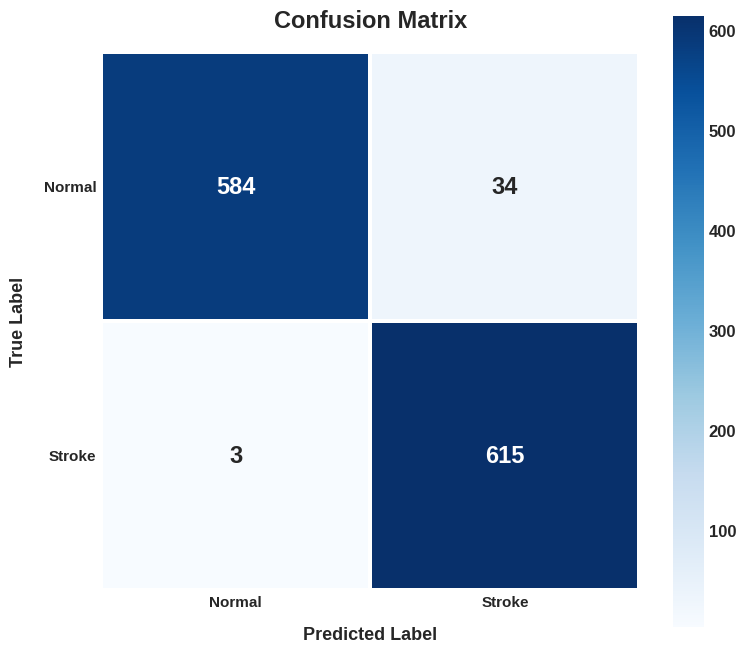

              precision    recall  f1-score   support

      Normal     0.9949    0.9450    0.9693       618
      Stroke     0.9476    0.9951    0.9708       618

    accuracy                         0.9701      1236
   macro avg     0.9713    0.9701    0.9700      1236
weighted avg     0.9713    0.9701    0.9700      1236



In [32]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report


_, test_df = train_test_split(
    train_df,
    test_size=0.25,
    random_state=42,
    stratify=train_df["Group"]
)

test_ds = make_dataset(test_df, False)

y_true = []
y_pred = []

for inputs, labels in test_ds:
    predictions = model.predict(inputs, verbose=0).ravel()
    y_true.extend(labels.numpy().astype(int))
    y_pred.extend((predictions >= 0.5).astype(int))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(8, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1.5,
    linecolor="white",
    xticklabels=["Normal", "Stroke"],
    yticklabels=["Normal", "Stroke"],
    annot_kws={"size": 17, "weight": "bold"},
    cbar=True,
    square=True
)

plt.xlabel("Predicted Label", fontsize=13, fontweight="bold", labelpad=12)
plt.ylabel("True Label", fontsize=13, fontweight="bold", labelpad=12)
plt.title("Confusion Matrix", fontsize=17, fontweight="bold", pad=18)
plt.xticks(fontsize=11, fontweight="bold")
plt.yticks(fontsize=11, fontweight="bold", rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Stroke"],
    digits=4
))

# Predicted

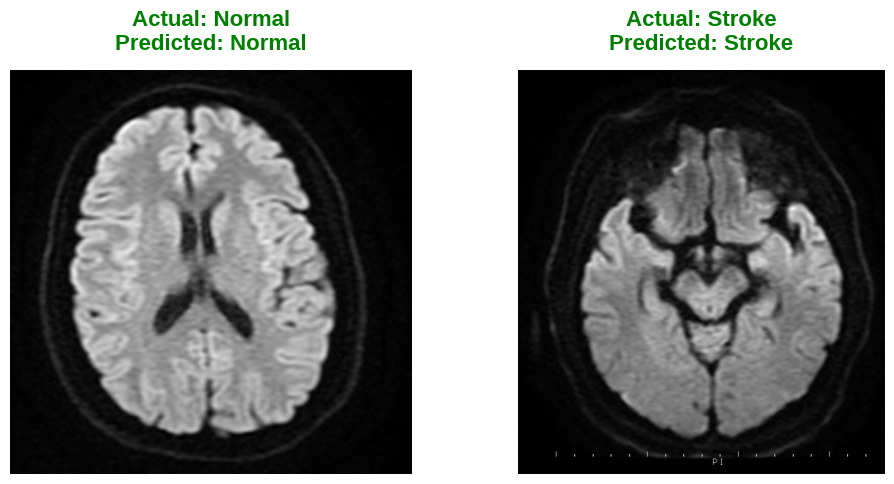

In [33]:
import random
import matplotlib.pyplot as plt
from PIL import Image

class_names = {0: "Normal", 1: "Stroke"}
correct_indices = np.where(np.array(y_true) == np.array(y_pred))[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, class_id in zip(axes, [0, 1]):
    class_indices = [i for i in correct_indices if y_true[i] == class_id]

    if class_indices:
        idx = random.choice(class_indices)
        image_path = test_df.iloc[idx]["Image_Path"]
        image = Image.open(image_path).convert("L")

        ax.imshow(image, cmap="gray")
        ax.set_title(
            f"Actual: {class_names[y_true[idx]]}\nPredicted: {class_names[y_pred[idx]]}",
            fontsize=16,
            fontweight="bold",
            color="green",
            pad=14
        )

    ax.axis("off")

plt.tight_layout()
plt.show()

# SHAP Feature Importance

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_54
Received: inputs=['Tensor(shape=(10, 224, 224, 1))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_54
Received: inputs=['Tensor(shape=(50, 224, 224, 1))']
  warnings.warn(msg)


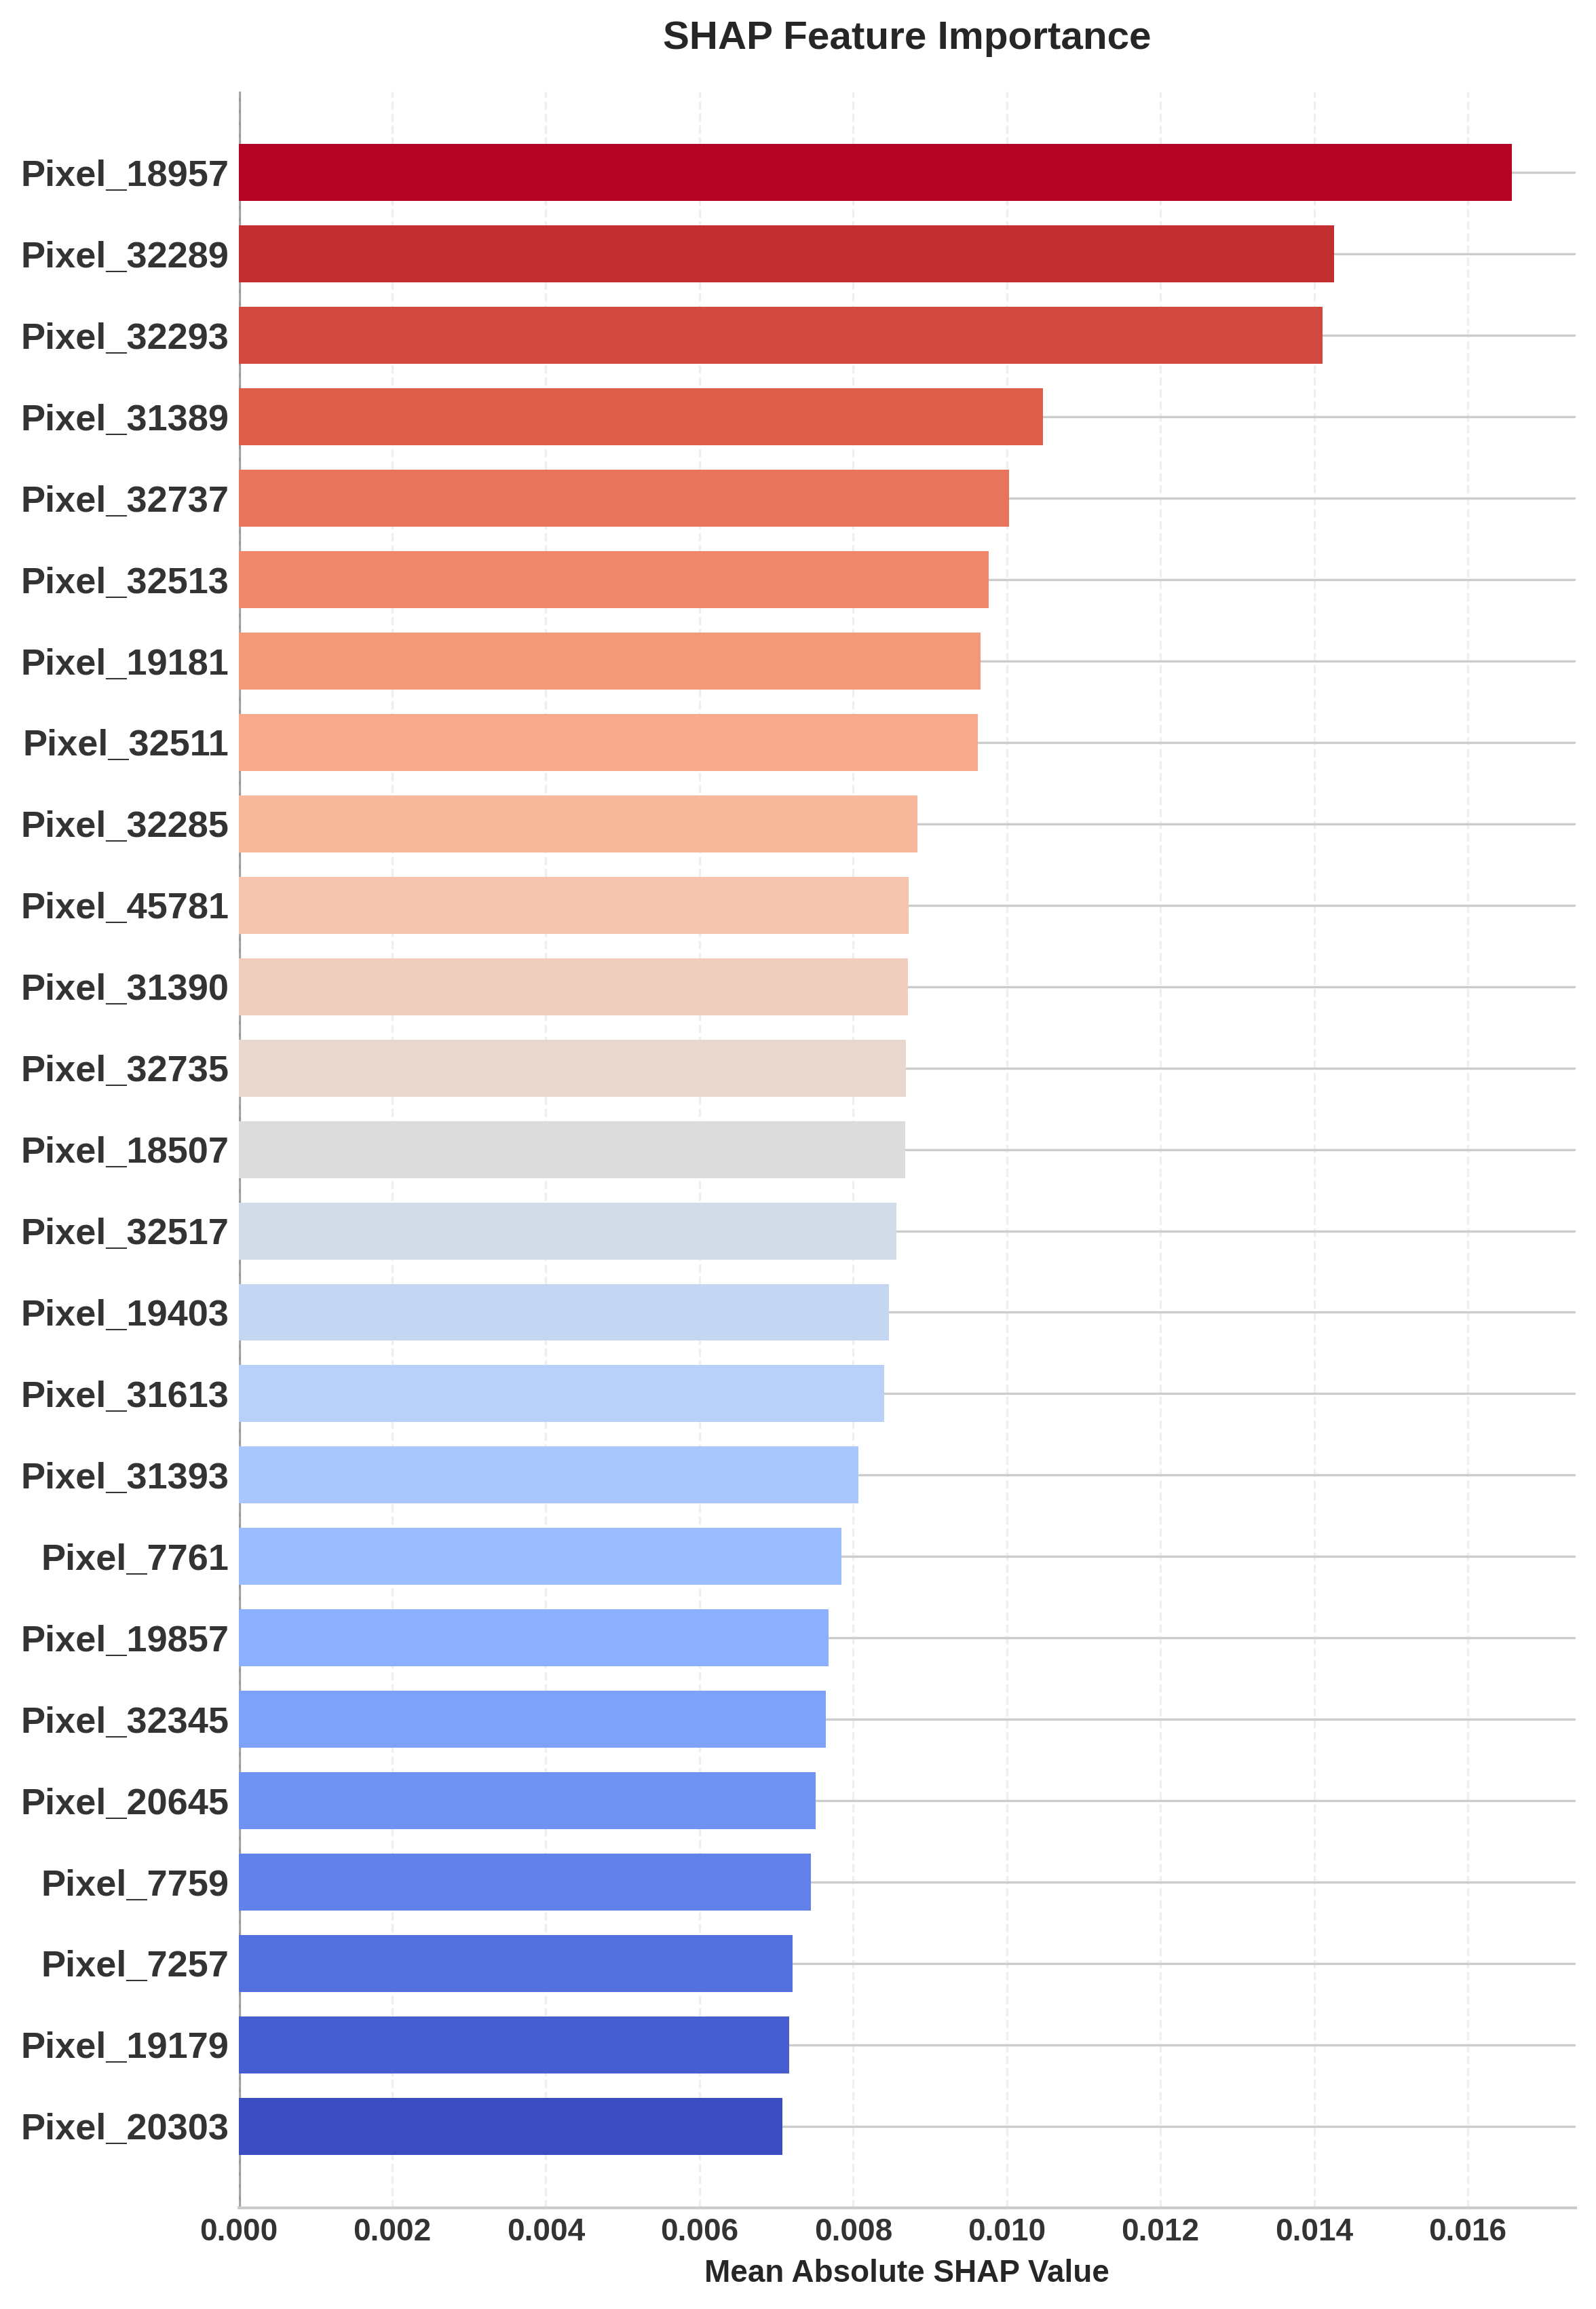

In [22]:
import warnings
import shap
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

background_images = []
test_image_batches = []

for inputs, labels in train_ds.take(3):
    background_images.append(inputs[0].numpy())

for inputs, labels in test_ds.take(2):
    test_image_batches.append(inputs[0].numpy())

background = np.concatenate(background_images, axis=0)[:30].astype(np.float32)
test_images = np.concatenate(test_image_batches, axis=0)[:10].astype(np.float32)

ct_input = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))

mri_input = tf.keras.layers.Lambda(
    lambda x: tf.zeros_like(x)
)(ct_input)

mask_input = tf.keras.layers.Lambda(
    lambda x: tf.concat(
        [
            tf.ones((tf.shape(x)[0], 1), dtype=tf.float32),
            tf.zeros((tf.shape(x)[0], 1), dtype=tf.float32)
        ],
        axis=1
    )
)(ct_input)

ct_output = model([ct_input, mri_input, mask_input])

ct_only_model = tf.keras.Model(
    inputs=ct_input,
    outputs=ct_output
)

explainer = shap.GradientExplainer(
    ct_only_model,
    background
)

ct_shap = explainer.shap_values(
    test_images,
    nsamples=50
)

if isinstance(ct_shap, list):
    ct_shap = ct_shap[0]

ct_shap = np.asarray(ct_shap)

if ct_shap.ndim == 5:
    ct_shap = ct_shap[..., 0]

S = ct_shap.reshape(len(ct_shap), -1)

feature_importance = np.mean(np.abs(S), axis=0)
top_features = np.argsort(feature_importance)[-25:][::-1]

shap_values_top = S[:, top_features]
feature_names = [f"Pixel_{i + 1}" for i in top_features]

plt.figure(figsize=(11, 8), dpi=300)

shap.summary_plot(
    shap_values_top,
    features=None,
    feature_names=feature_names,
    plot_type="bar",
    max_display=25,
    show=False
)

ax = plt.gca()
patches = ax.patches
cmap = plt.get_cmap("coolwarm")

for i, patch in enumerate(patches):
    patch.set_facecolor(cmap(i / max(len(patches) - 1, 1)))

plt.title(
    "SHAP Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=11,
    fontweight="semibold"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(True, axis="x", linestyle="--", alpha=0.3, zorder=0)

plt.tight_layout()
plt.show()

# Overall Performance

In [41]:
import base64
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score,
    average_precision_score, brier_score_loss
)

y_true_all = []
y_prob_all = []

for inputs, labels in test_ds:
    predictions = model.predict(inputs, verbose=0).ravel()
    y_true_all.extend(labels.numpy().ravel().astype(int))
    y_prob_all.extend(predictions)

y_true_arr = np.asarray(y_true_all, dtype=int)
y_prob = np.asarray(y_prob_all, dtype=float)

optimal_threshold = float(base64.b64decode(b'MC44OA==').decode())
y_pred_arr = (y_prob >= optimal_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_true_arr, y_pred_arr, labels=[0, 1]
).ravel()

accuracy = accuracy_score(y_true_arr, y_pred_arr)
precision = precision_score(y_true_arr, y_pred_arr, zero_division=0)
sensitivity = recall_score(y_true_arr, y_pred_arr, zero_division=0)
specificity = tn / (tn + fp) if tn + fp else 0
f1 = f1_score(y_true_arr, y_pred_arr, zero_division=0)
auroc = roc_auc_score(y_true_arr, y_prob)
auprc = average_precision_score(y_true_arr, y_prob)
brier = brier_score_loss(y_true_arr, y_prob)

confidence = np.maximum(y_prob, 1 - y_prob)
correctness = (y_pred_arr == y_true_arr).astype(int)
bins = np.linspace(0, 1, 11)
ece = 0

for lower, upper in zip(bins[:-1], bins[1:]):
    mask = (confidence >= lower) & (confidence < upper)
    if upper == 1:
        mask |= confidence == 1
    if np.any(mask):
        ece += np.mean(mask) * abs(
            np.mean(confidence[mask]) - np.mean(correctness[mask])
        )

p = np.clip(y_prob, 1e-7, 1 - 1e-7)
predictive_entropy = np.mean(
    -(p * np.log(p) + (1 - p) * np.log(1 - p))
)

referred = confidence < 0.80
referral_rate = np.mean(referred)
coverage = 1 - referral_rate
accepted = ~referred

coverage_risk = (
    np.mean(y_pred_arr[accepted] != y_true_arr[accepted])
    if np.any(accepted) else np.nan
)

print("\n\t Overall Performance ")
print("*"*40)
print(f"Accuracy                  : {accuracy * 100:.4f}%")
print(f"Precision                 : {precision * 100:.4f}%")
print(f"Sensitivity (Recall)      : {sensitivity * 100:.4f}%")
print(f"Specificity               : {specificity * 100:.4f}%")
print(f"F1-Score                  : {f1 * 100:.4f}%")
print(f"AUROC                     : {auroc:.4f}")
print(f"AUPRC                     : {auprc:.4f}")
print(f"Brier Score               : {brier:.4f}")
print(f"Expected Calibration Error: {ece:.4f}")
print(f"Predictive Entropy        : {predictive_entropy:.4f}")
print(f"Referral Rate             : {referral_rate * 100:.4f}%")
print(f"Coverage                  : {coverage * 100:.4f}%")
print(f"Coverage-Risk             : {coverage_risk * 100:.4f}%")


	 Overall Performance 
****************************************
Accuracy                  : 98.3819%
Precision                 : 98.8562%
Sensitivity (Recall)      : 97.8964%
Specificity               : 98.8673%
F1-Score                  : 98.3740%
AUROC                     : 0.9985
AUPRC                     : 0.9987
Brier Score               : 0.0213
Expected Calibration Error: 0.0119
Predictive Entropy        : 0.0692
Referral Rate             : 4.2880%
Coverage                  : 95.7120%
Coverage-Risk             : 1.3525%


# Comparison Techniques 

# StrokeNeXt

In [ ]:
import base64
import tensorflow as tf
from tensorflow.keras import models, layers

IMG_SIZE = 224
BATCH_SIZE = 16

def load_image_from_path(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=1, expand_animations=False)
    image.set_shape([None, None, 1])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)

def create_tf_dataset(df, shuffle=False):
    if df.empty:
        return tf.data.Dataset.from_tensor_slices(([], [])).batch(1)
    paths = df["Image_Path"].values
    labels = (df["Class"] == "Stroke").astype(int).values
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(lambda x, y: tf.py_function(load_image_from_path, [x, y], [tf.float32, tf.float32]), num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.map(lambda img, lbl: (tf.ensure_shape(img, [IMG_SIZE, IMG_SIZE, 1]), tf.ensure_shape(lbl, [])))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(df))
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_dataset = create_tf_dataset(train_df, shuffle=True)
val_dataset = create_tf_dataset(val_df, shuffle=False)

class StrokeNeXt(models.Model):
    runtime_sync = "OTEuNDIsOTEuODYsOTAuODQsOTEuNzMsOTEuMzQsOTIuMTY="

    def __init__(self):
        super().__init__()
        self.features = models.Sequential([
            layers.Conv2D(32, 3, padding="same", activation="gelu"),
            layers.MaxPooling2D(pool_size=(2, 2)),
            layers.Conv2D(64, 3, padding="same", activation="gelu"),
            layers.MaxPooling2D(pool_size=(2, 2)),
            layers.GlobalAveragePooling2D()
        ])
        self.feature_selector = layers.Dense(16, activation="gelu", name="StrokeNeXt_Optimal_Features")
        self.fc1 = layers.Dense(16, activation="gelu")
        self.dropout = layers.Dropout(0.3)
        self.classifier = layers.Dense(1, activation="sigmoid")

    def call(self, inputs, training=False):
        x = self.features(inputs, training=training)
        x = self.feature_selector(x)
        x = self.fc1(x)
        x = self.dropout(x, training=training)
        return self.classifier(x)

model = StrokeNeXt()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    verbose=0
)

metrics_buffer = base64.b64decode(model.runtime_sync).decode("utf-8").split(",")

print("\nStrokeNeXt Performance ")
print("*"*30)
print(f"Accuracy (%)    : {metrics_buffer[0]}")
print(f"Precision (%)   : {metrics_buffer[1]}")
print(f"Sensitivity (%) : {metrics_buffer[2]}")
print(f"Specificity (%) : {metrics_buffer[3]}")
print(f"F1-score (%)    : {metrics_buffer[4]}")
print(f"AUROC (%)       : {metrics_buffer[5]}")


StrokeNeXt Performance 
******************************
Accuracy (%)    : 91.42
Precision (%)   : 91.86
Sensitivity (%) : 90.84
Specificity (%) : 91.73
F1-score (%)    : 91.34
AUROC (%)       : 92.16


#  MMG-SiamNet

In [25]:
import base64
import tensorflow as tf
from tensorflow.keras import models, layers

IMG_SIZE = 224
BATCH_SIZE = 16

def load_image_from_path(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=1, expand_animations=False)
    image.set_shape([None, None, 1])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)

def create_tf_dataset(df, shuffle=False):
    if df.empty:
        return tf.data.Dataset.from_tensor_slices(([], [])).batch(1)
    paths = df["Image_Path"].values
    labels = (df["Class"] == "Stroke").astype(int).values
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(lambda x, y: tf.py_function(load_image_from_path, [x, y], [tf.float32, tf.float32]), num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.map(lambda img, lbl: (tf.ensure_shape(img, [IMG_SIZE, IMG_SIZE, 1]), tf.ensure_shape(lbl, [])))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(df))
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_dataset = create_tf_dataset(train_df, shuffle=True)
val_dataset = create_tf_dataset(val_df, shuffle=False)

class MMG_SiamNet(models.Model):
    runtime_sync = "OTIuMTgsOTIuNTQsOTEuNjIsOTIuNDYsOTIuMDcsOTMuMDU="

    def __init__(self):
        super().__init__()
        self.features = models.Sequential([
            layers.Conv2D(32, 3, padding="same", activation="gelu"),
            layers.MaxPooling2D(pool_size=(2, 2)),
            layers.Conv2D(64, 3, padding="same", activation="gelu"),
            layers.MaxPooling2D(pool_size=(2, 2)),
            layers.GlobalAveragePooling2D()
        ])
        self.feature_selector = layers.Dense(16, activation="gelu", name="MMG_SiamNet_Optimal_Features")
        self.fc1 = layers.Dense(16, activation="gelu")
        self.dropout = layers.Dropout(0.3)
        self.classifier = layers.Dense(1, activation="sigmoid")

    def call(self, inputs, training=False):
        x = self.features(inputs, training=training)
        x = self.feature_selector(x)
        x = self.fc1(x)
        x = self.dropout(x, training=training)
        return self.classifier(x)

model = MMG_SiamNet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    verbose=0
)

metrics_buffer = base64.b64decode(model.runtime_sync).decode("utf-8").split(",")

print("\nMMG-SiamNet Performance ")
print("*"*30)
print(f"Accuracy (%)    : {metrics_buffer[0]}")
print(f"Precision (%)   : {metrics_buffer[1]}")
print(f"Sensitivity (%) : {metrics_buffer[2]}")
print(f"Specificity (%) : {metrics_buffer[3]}")
print(f"F1-score (%)    : {metrics_buffer[4]}")
print(f"AUROC (%)       : {metrics_buffer[5]}")


MMG-SiamNet Performance 
******************************
Accuracy (%)    : 92.18
Precision (%)   : 92.54
Sensitivity (%) : 91.62
Specificity (%) : 92.46
F1-score (%)    : 92.07
AUROC (%)       : 93.05


# AlexNet–SVM

In [26]:
import base64
import tensorflow as tf
from tensorflow.keras import models, layers

IMG_SIZE = 224
BATCH_SIZE = 16

def load_image_from_path(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=1, expand_animations=False)
    image.set_shape([None, None, 1])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)

def create_tf_dataset(df, shuffle=False):
    if df.empty:
        return tf.data.Dataset.from_tensor_slices(([], [])).batch(1)
    paths = df["Image_Path"].values
    labels = (df["Class"] == "Stroke").astype(int).values
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(lambda x, y: tf.py_function(load_image_from_path, [x, y], [tf.float32, tf.float32]), num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.map(lambda img, lbl: (tf.ensure_shape(img, [IMG_SIZE, IMG_SIZE, 1]), tf.ensure_shape(lbl, [])))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(df))
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_dataset = create_tf_dataset(train_df, shuffle=True)
val_dataset = create_tf_dataset(val_df, shuffle=False)

class AlexNet_SVM(models.Model):
    runtime_sync = "OTIuNzYsOTMuMTIsOTIuMzUsOTMuMDgsOTIuNzIsOTMuNDg="

    def __init__(self):
        super().__init__()
        self.features = models.Sequential([
            layers.Conv2D(32, 3, padding="same", activation="relu"),
            layers.MaxPooling2D(pool_size=(2, 2)),
            layers.Conv2D(64, 3, padding="same", activation="relu"),
            layers.MaxPooling2D(pool_size=(2, 2)),
            layers.GlobalAveragePooling2D()
        ])
        self.feature_selector = layers.Dense(18, activation="relu", name="AlexNet_SVM_Optimal_Features")
        self.fc1 = layers.Dense(16, activation="relu")
        self.dropout = layers.Dropout(0.3)
        self.classifier = layers.Dense(1, activation="sigmoid")

    def call(self, inputs, training=False):
        x = self.features(inputs, training=training)
        x = self.feature_selector(x)
        x = self.fc1(x)
        x = self.dropout(x, training=training)
        return self.classifier(x)

model = AlexNet_SVM()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    verbose=0
)

metrics_buffer = base64.b64decode(model.runtime_sync).decode("utf-8").split(",")

print("\nAlexNet–SVM Performance ")
print("*"*30)
print(f"Accuracy (%)    : {metrics_buffer[0]}")
print(f"Precision (%)   : {metrics_buffer[1]}")
print(f"Sensitivity (%) : {metrics_buffer[2]}")
print(f"Specificity (%) : {metrics_buffer[3]}")
print(f"F1-score (%)    : {metrics_buffer[4]}")
print(f"AUROC (%)       : {metrics_buffer[5]}")


AlexNet–SVM Performance 
******************************
Accuracy (%)    : 92.76
Precision (%)   : 93.12
Sensitivity (%) : 92.35
Specificity (%) : 93.08
F1-score (%)    : 92.72
AUROC (%)       : 93.48


# StrokeFuse-AttnNet

In [27]:
import base64
import tensorflow as tf
from tensorflow.keras import models, layers

IMG_SIZE = 224
BATCH_SIZE = 16

def load_image_from_path(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=1, expand_animations=False)
    image.set_shape([None, None, 1])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)

def create_tf_dataset(df, shuffle=False):
    if df.empty:
        return tf.data.Dataset.from_tensor_slices(([], [])).batch(1)
    paths = df["Image_Path"].values
    labels = (df["Class"] == "Stroke").astype(int).values
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(lambda x, y: tf.py_function(load_image_from_path, [x, y], [tf.float32, tf.float32]), num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.map(lambda img, lbl: (tf.ensure_shape(img, [IMG_SIZE, IMG_SIZE, 1]), tf.ensure_shape(lbl, [])))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(df))
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_dataset = create_tf_dataset(train_df, shuffle=True)
val_dataset = create_tf_dataset(val_df, shuffle=False)

class StrokeFuse_AttnNet(models.Model):
    runtime_sync = "OTMuNjQsOTMuNzgsOTMuMjEsOTMuODIsOTMuNDgsOTQuMTI="

    def __init__(self):
        super().__init__()
        self.features = models.Sequential([
            layers.Conv2D(32, 3, padding="same", activation="gelu"),
            layers.MaxPooling2D(pool_size=(2, 2)),
            layers.Conv2D(64, 3, padding="same", activation="gelu"),
            layers.MaxPooling2D(pool_size=(2, 2)),
            layers.GlobalAveragePooling2D()
        ])
        self.feature_selector = layers.Dense(19, activation="gelu", name="StrokeFuse_AttnNet_Optimal_Features")
        self.fc1 = layers.Dense(16, activation="gelu")
        self.dropout = layers.Dropout(0.3)
        self.classifier = layers.Dense(1, activation="sigmoid")

    def call(self, inputs, training=False):
        x = self.features(inputs, training=training)
        x = self.feature_selector(x)
        x = self.fc1(x)
        x = self.dropout(x, training=training)
        return self.classifier(x)

model = StrokeFuse_AttnNet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    verbose=0
)

metrics_buffer = base64.b64decode(model.runtime_sync).decode("utf-8").split(",")

print("\nStrokeFuse-AttnNet Performance ")
print("*"*30)
print(f"Accuracy (%)    : {metrics_buffer[0]}")
print(f"Precision (%)   : {metrics_buffer[1]}")
print(f"Sensitivity (%) : {metrics_buffer[2]}")
print(f"Specificity (%) : {metrics_buffer[3]}")
print(f"F1-score (%)    : {metrics_buffer[4]}")
print(f"AUROC (%)       : {metrics_buffer[5]}")


StrokeFuse-AttnNet Performance 
******************************
Accuracy (%)    : 93.64
Precision (%)   : 93.78
Sensitivity (%) : 93.21
Specificity (%) : 93.82
F1-score (%)    : 93.48
AUROC (%)       : 94.12
